In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import glob
import re
from collections import defaultdict
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import polars as pl
from scipy.optimize import minimize
import joblib
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

In [2]:
mc_path = "Regions_MC_ver3"
data_path = "Regions_data_ver4"

mc_processes = ["Diboson", "Multijet", "Single_top", "ttbar", "Wjets", "Zjets"]

columns_to_load_mc = [
    "raw_weights", 
    "weight_sub",
    "met_recalc_pt", "met_recalc_phi",
    "ht",
    
    "signal_jet_pt", 
    "signal_jet_eta", 
    "signal_jet_phi", 

    "AnalysisLargeRJetsAuxDyn_Tau1_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau2_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau3_wta"
]


columns_to_load_data = [
    "met_recalc_pt", "met_recalc_phi",
    "ht",
    "signal_jet_pt", 
    "signal_jet_eta", 
    "signal_jet_phi", 

    "AnalysisLargeRJetsAuxDyn_Tau1_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau2_wta", 
    "AnalysisLargeRJetsAuxDyn_Tau3_wta"
]

In [3]:
### --- Loading MC events --- ###
MC_ATLAS_CR0L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_MJRR", "*.parquet"))
MC_ATLAS_CR1L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_1L", "*.parquet"))
MC_ATLAS_CR1L1B_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_1L1B", "*.parquet"))
MC_ATLAS_CR2L_paths = glob.glob(os.path.join(mc_path, "ATLAS_CR_2L", "*.parquet"))

MC_SR_paths = glob.glob(os.path.join(mc_path, "SR", "*.parquet"))

### --- Loading data events --- ###
DATA_ATLAS_CR0L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_MJRR", "*.parquet"))
DATA_ATLAS_CR1L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_1L", "*.parquet"))
DATA_ATLAS_CR1L1B_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_1L1B", "*.parquet"))
DATA_ATLAS_CR2L_paths = glob.glob(os.path.join(data_path, "ATLAS_CR_2L", "*.parquet"))

DATA_SR_paths = glob.glob(os.path.join(data_path, "SR_0L", "*.parquet"))

# Check that we loaded the paths correctly
if not (MC_ATLAS_CR0L_paths and MC_ATLAS_CR1L_paths and MC_ATLAS_CR1L1B_paths and MC_ATLAS_CR2L_paths and MC_SR_paths):
    raise ValueError("Error: One or more MC paths are empty. Please check the paths.")

if not (DATA_ATLAS_CR0L_paths and DATA_ATLAS_CR1L_paths and DATA_ATLAS_CR1L1B_paths and DATA_ATLAS_CR2L_paths and DATA_SR_paths):
    raise ValueError("Error: One or more data paths are empty. Please check the paths.")

print("Paths loaded successfully!")

Paths loaded successfully!


In [4]:
def uniform_fallback(seed: int, low: float = -0.10, high: float = -0.01) -> pl.Expr:
    """
    Generates a reproducible, continuous uniform number in [low, high)
    compatible with Polars LazyFrame streaming execution.
    """
    u01 = (pl.struct(["met_recalc_pt", "ht"]).hash(seed=seed) % 100_000).cast(pl.Float64) / 100_000.0
    return low + (high - low) * u01


def calc_features(lf: pl.LazyFrame, is_MC: bool) -> pl.LazyFrame:
    """
    Calculates Mjj and tau ratios using the cleaned Parquet features, 
    then discards all low-level vectors.
    """
    lf = lf.with_columns(
        j1_pt  = pl.col("signal_jet_pt").list.get(0, null_on_oob=True),
        j2_pt  = pl.col("signal_jet_pt").list.get(1, null_on_oob=True),
        j1_eta = pl.col("signal_jet_eta").list.get(0, null_on_oob=True),
        j2_eta = pl.col("signal_jet_eta").list.get(1, null_on_oob=True),
        j1_phi = pl.col("signal_jet_phi").list.get(0, null_on_oob=True),
        j2_phi = pl.col("signal_jet_phi").list.get(1, null_on_oob=True),

        lrj1_t1 = pl.col("AnalysisLargeRJetsAuxDyn_Tau1_wta").list.get(0, null_on_oob=True),
        lrj1_t2 = pl.col("AnalysisLargeRJetsAuxDyn_Tau2_wta").list.get(0, null_on_oob=True),
        lrj1_t3 = pl.col("AnalysisLargeRJetsAuxDyn_Tau3_wta").list.get(0, null_on_oob=True),
        lrj2_t1 = pl.col("AnalysisLargeRJetsAuxDyn_Tau1_wta").list.get(1, null_on_oob=True),
        lrj2_t2 = pl.col("AnalysisLargeRJetsAuxDyn_Tau2_wta").list.get(1, null_on_oob=True),
        lrj2_t3 = pl.col("AnalysisLargeRJetsAuxDyn_Tau3_wta").list.get(1, null_on_oob=True),
    )

    mjj_sq = (
        2 * pl.col("j1_pt") * pl.col("j2_pt") * (
            (pl.col("j1_eta") - pl.col("j2_eta")).cosh() - (pl.col("j1_phi") - pl.col("j2_phi")).cos()
        )
    )

    lf = lf.with_columns(
        mjj = pl.when(mjj_sq > 0).then(mjj_sq.sqrt()).otherwise(0.0),

        # Use smooth uniform noise in [-0.10, -0.01) when denominator <= 0 or null
        ljet1_tau21 = pl.when(pl.col("lrj1_t1") > 0).then(pl.col("lrj1_t2") / pl.col("lrj1_t1")).otherwise(uniform_fallback(seed=1)),
        ljet1_tau32 = pl.when(pl.col("lrj1_t2") > 0).then(pl.col("lrj1_t3") / pl.col("lrj1_t2")).otherwise(uniform_fallback(seed=2)),
        ljet2_tau21 = pl.when(pl.col("lrj2_t1") > 0).then(pl.col("lrj2_t2") / pl.col("lrj2_t1")).otherwise(uniform_fallback(seed=3)),
        ljet2_tau32 = pl.when(pl.col("lrj2_t2") > 0).then(pl.col("lrj2_t3") / pl.col("lrj2_t2")).otherwise(uniform_fallback(seed=4)),
    )

    final_columns = (
        ["mc_process", "subprocess", "raw_weights", "weight_sub"] if is_MC else []
    ) + [
        "met_recalc_pt", "met_recalc_phi", "ht", "mjj",
        "ljet1_tau21", "ljet1_tau32", "ljet2_tau21", "ljet2_tau32"
    ]
        
    return lf.select(final_columns)

def get_lazyframes(paths, is_mc):
    files_by_meta = defaultdict(list)
    known_processes = ['Wjets', 'Zjets', 'ttbar', 'Diboson', 'Multijet', 'Single_top']
    
    for filepath in paths:
        filename = os.path.basename(filepath)
        
        if is_mc:
            mc_process = next((p for p in known_processes if filename.startswith(p)), "Other")
            name_no_ext = filename.replace(".parquet", "") 
            if name_no_ext.startswith(mc_process + "_"):
                remainder = name_no_ext[len(mc_process) + 1:]
            else:
                remainder = name_no_ext  
            subprocess = re.sub(r"_batch\d+$", "", remainder) 
            files_by_meta[(mc_process, subprocess)].append(filepath)
        else:
            files_by_meta[("Data", "Data")].append(filepath)

    lazy_frames = []
    for (mc_process, subprocess), group_paths in files_by_meta.items():
        # 1. Add aggressive parallelization to the parquet reader
        if is_mc:
            lf = pl.scan_parquet(group_paths, parallel="row_groups").select(columns_to_load_mc)
            lf = lf.with_columns(
                pl.lit(mc_process).alias("mc_process"),
                pl.lit(subprocess).alias("subprocess")
            )
        else:
            lf = pl.scan_parquet(group_paths, parallel="row_groups").select(columns_to_load_data)
            
        lf = calc_features(lf, is_mc)
        lazy_frames.append(lf)

    return lazy_frames

#### Process CR1L

In [5]:
MC_ATLAS_CR1L_lazy = get_lazyframes(MC_ATLAS_CR1L_paths, is_mc=True)
DATA_ATLAS_CR1L_lazy = get_lazyframes(DATA_ATLAS_CR1L_paths, is_mc=False)

MC_ATLAS_CR1L = pl.concat(MC_ATLAS_CR1L_lazy).collect(engine="streaming")
DATA_ATLAS_CR1L = pl.concat(DATA_ATLAS_CR1L_lazy).collect(engine="streaming")

#### Process CR1L1B

In [6]:
MC_ATLAS_CR1L1B_lazy = get_lazyframes(MC_ATLAS_CR1L1B_paths, is_mc=True)
DATA_ATLAS_CR1L1B_lazy = get_lazyframes(DATA_ATLAS_CR1L1B_paths, is_mc=False)

MC_ATLAS_CR1L1B = pl.concat(MC_ATLAS_CR1L1B_lazy).collect(engine="streaming")
DATA_ATLAS_CR1L1B = pl.concat(DATA_ATLAS_CR1L1B_lazy).collect(engine="streaming")

#### Process CR2L

In [7]:
MC_ATLAS_CR2L_lazy = get_lazyframes(MC_ATLAS_CR2L_paths, is_mc=True)
DATA_ATLAS_CR2L_lazy = get_lazyframes(DATA_ATLAS_CR2L_paths, is_mc=False)

MC_ATLAS_CR2L = pl.concat(MC_ATLAS_CR2L_lazy).collect(engine="streaming")
DATA_ATLAS_CR2L = pl.concat(DATA_ATLAS_CR2L_lazy).collect(engine="streaming")

#### Process CR0L

In [8]:
# MC_ATLAS_CR0L_lazy = get_lazyframes(MC_ATLAS_CR0L_paths, is_mc=True)
# DATA_ATLAS_CR0L_lazy = get_lazyframes(DATA_ATLAS_CR0L_paths, is_mc=False)

# MC_ATLAS_CR0L = pl.concat(MC_ATLAS_CR0L_lazy).collect(engine="streaming")
# DATA_ATLAS_CR0L = pl.concat(DATA_ATLAS_CR0L_lazy).collect(engine="streaming")

#### Process SR

In [9]:
MC_SR_lazy = get_lazyframes(MC_SR_paths, is_mc=True)
DATA_SR_lazy = get_lazyframes(DATA_SR_paths, is_mc=False)

MC_SR = pl.concat(MC_SR_lazy).collect(engine="streaming")
DATA_SR = pl.concat(DATA_SR_lazy).collect(engine="streaming")

In [10]:
meta_df = pl.read_csv("metadata_processed.csv").select([
    "physics_short", 
    "crossSection_pb", 
    "genFiltEff", 
    "kFactor",
    "sumOfWeights",
    "sum_w_pros", 
    "scale_factor_sub_weight", 
    "luminosity"
]).rename({"physics_short": "subprocess"})

def plot_mc_data_comparison(df_mc: pl.DataFrame, df_data: pl.DataFrame, region_name: str = "", lumi_data: int = 0):
    """
    Plots Data vs MC using native ATLAS scale factor calculations.
    Saves individual, thesis-ready PDFs for each variable with dynamic legend spacing,
    automatic log-scale handling, and MC Statistical uncertainty bands.
    """
    
    # Thesis/Publication styling settings
    plt.rcParams.update({
        'font.size': 14,
        'axes.labelsize': 16,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'legend.fontsize': 12,
        'lines.linewidth': 1.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'axes.formatter.use_mathtext': True,
        'axes.linewidth': 1.2,
        'hatch.linewidth': 0.5 # Thinner hatch lines look cleaner
    })
    
    variables = [
        'ht', 'met_recalc_pt', 'mjj', 
        'ljet1_tau21', 'ljet1_tau32', 'ljet2_tau21', 'ljet2_tau32'
    ]
    
    log_variables = ['ht', 'met_recalc_pt', 'mjj']
    mc_processes = ["Diboson", "Single_top", "ttbar", "Zjets", "Wjets", "Multijet"]
    
    color_map = {
        "Diboson": "#e31a1c", "Multijet": "#fdbf6f", "Single_top": "#ff7f00",
        "ttbar": "#cab2d6", "Wjets": "#33a02c", "Zjets": "#1f78b4"
    }
    
    pretty_labels = {
        'ht': r'$H_{T}$ [GeV]', 'met_recalc_pt': r'$E_{T}^{\text{miss}}$ [GeV]',
        'mjj': r'$m_{jj}$ [GeV]', 'ljet1_tau21': r'Leading jet $\tau_{21}$',
        'ljet1_tau32': r'Leading jet $\tau_{32}$', 'ljet2_tau21': r'Subleading jet $\tau_{21}$',
        'ljet2_tau32': r'Subleading jet $\tau_{32}$'
    }

    for branch in variables:
        valid_mc_df = df_mc.filter(pl.col(branch).is_not_null())
        valid_data_df = df_data.filter(pl.col(branch).is_not_null())
        
        valid_mc_arr = valid_mc_df.get_column(branch).to_numpy()
        valid_data_arr = valid_data_df.get_column(branch).to_numpy()
        
        if len(valid_mc_arr) == 0 and len(valid_data_arr) == 0:
            continue
            
        combined_data = np.concatenate([valid_mc_arr, valid_data_arr])
        bins = np.histogram_bin_edges(combined_data, bins=15)
        bin_centers = (bins[:-1] + bins[1:]) / 2
        bin_widths = np.diff(bins) 
        
        fig = plt.figure(figsize=(8, 8))
        gs = gridspec.GridSpec(2, 1, height_ratios=[3.5, 1], hspace=0.08)
        
        ax_main = fig.add_subplot(gs[0])
        ax_ratio = fig.add_subplot(gs[1], sharex=ax_main)
        
        mc_hists = []
        mc_weights = []
        labels = []
        
        for proc in mc_processes:
            proc_df = valid_mc_df.filter(pl.col('mc_process') == proc)
            if proc_df.height == 0: continue
                
            mc_hists.append(proc_df.get_column(branch).to_numpy())
            mc_weights.append(proc_df.get_column('final_weight').to_numpy())
            labels.append(proc)
            
        mc_colors = [color_map.get(l, '#999999') for l in labels]
        if mc_hists:
            ax_main.hist(
                mc_hists, bins=bins, weights=mc_weights, 
                stacked=True, label=labels, color=mc_colors, 
                histtype='stepfilled', edgecolor='black', linewidth=0.5
            )
        
        # --- MC STATISTICAL UNCERTAINTY ONLY ---
        mc_total_weights = valid_mc_df.get_column('final_weight').to_numpy() if 'final_weight' in valid_mc_df.columns else np.ones_like(valid_mc_arr)
        total_mc, _ = np.histogram(valid_mc_arr, bins=bins, weights=mc_total_weights)
        
        # Stat error: sum of squared weights per bin
        mc_stat_var, _ = np.histogram(valid_mc_arr, bins=bins, weights=mc_total_weights**2)
        mc_err = np.sqrt(mc_stat_var) # Just the stat error

        ax_main.bar(bin_centers, 2 * mc_err, bottom=total_mc - mc_err, width=bin_widths,
                    color='none', edgecolor='gray', hatch='////', linewidth=0,
                    alpha=0.5, zorder=5, label='Stat. Unc.')
        # ---------------------------------------

        counts_data, _ = np.histogram(valid_data_arr, bins=bins)
        ax_main.errorbar(
            bin_centers, counts_data, yerr=np.sqrt(counts_data), 
            fmt='ko', label='Data', zorder=10, capsize=0, markersize=5
        )
        
        max_data = np.max(counts_data) + np.max(np.sqrt(counts_data)) if len(counts_data) > 0 else 0
        max_mc = np.max(total_mc + mc_err) if len(total_mc) > 0 else 0 
        y_max = max(max_data, max_mc)
        
        if branch in log_variables:
            ax_main.set_yscale('log')
            ax_main.set_ylim(0.1, y_max * 1000)
        else:
            ax_main.set_ylim(0, y_max * 1.55) 
            ax_main.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        ax_main.set_ylabel('Events / Bin')
        plt.setp(ax_main.get_xticklabels(), visible=False)
        ax_main.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        if region_name:
            # 1. Plot the bold region name
            ax_main.text(0.04, 0.94, f"{region_name}", transform=ax_main.transAxes,
                        fontsize=14, verticalalignment='top', fontweight='bold') 

            # 2. Plot the physics info slightly lower (adjusting y from 0.94 to ~0.89)
            textstr_physics = r"$\sqrt{s} = 13$ TeV" + ", " + rf"{lumi_data:.3f} fb$^{{-1}}$"
            ax_main.text(0.04, 0.89, textstr_physics, transform=ax_main.transAxes,
                        fontsize=14, verticalalignment='top')


            # textlumi = f"{lumi_data:.3f}"

        handles, loc_labels = ax_main.get_legend_handles_labels()
        if "Data" in loc_labels:
            data_idx = loc_labels.index("Data")
            handles.insert(0, handles.pop(data_idx))
            loc_labels.insert(0, loc_labels.pop(data_idx))
            
        ax_main.legend(handles, loc_labels, loc='upper right', frameon=False, ncol=2)

        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = counts_data / total_mc
            ratio_err = np.sqrt(counts_data) / total_mc
            ratio = np.where(total_mc > 0, ratio, np.nan)
            ratio_err = np.where(total_mc > 0, ratio_err, np.nan)

            rel_mc_err = np.where(total_mc > 0, mc_err / total_mc, 0)
        
        ax_ratio.bar(bin_centers, 2 * rel_mc_err, bottom=1.0 - rel_mc_err, width=bin_widths,
                     color='gray', hatch='////', edgecolor='none', alpha=0.3, zorder=1)
        
        ax_ratio.axhline(1, color='gray', linestyle='--', linewidth=1.0, zorder=2)
        ax_ratio.errorbar(bin_centers, ratio, yerr=ratio_err, fmt='ko', capsize=0, markersize=5, zorder=10)
        
        ax_ratio.set_ylabel('Data / MC')
        ax_ratio.set_xlabel(pretty_labels.get(branch, branch))
        ax_ratio.set_ylim(0.5, 1.5)
        ax_ratio.set_yticks([0.75, 1.0, 1.25])
        
        ax_ratio.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax_ratio.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        
        fig.align_ylabels((ax_main, ax_ratio))
        
        filename_region = f"_{region_name.replace(' ', '_')}" if region_name else ""
        save_name = f"data_mc_{branch}{filename_region}.pdf"
        plt.savefig(f"Final_Plots/{save_name}")
        plt.show()
        plt.close(fig)

In [11]:
def apply_initial_weights(df_mc: pl.DataFrame, meta_df: pl.DataFrame) -> pl.DataFrame:
    df_mc = df_mc.join(meta_df, on="subprocess", how="left")

    LUMI = 25.289004522843967
    
    df_mc = df_mc.with_columns(
        official_scale_factor = (
            pl.col("crossSection_pb") * LUMI * 1000 * pl.col("genFiltEff") * pl.col("kFactor")
        ) / pl.col("sum_w_pros")
    )

    return df_mc.with_columns(
        final_weight = pl.col("official_scale_factor") * pl.col("raw_weights")
    )

In [12]:
# Shared upper outlier cuts for all regions
upper_outlier_cuts = (
    (pl.col("met_recalc_pt") < 2000) &
    (pl.col("mjj") < 10000) &
    (pl.col("ht") < 4000)
)

MC_ATLAS_CR1L   = MC_ATLAS_CR1L.filter(upper_outlier_cuts)
DATA_ATLAS_CR1L = DATA_ATLAS_CR1L.filter(upper_outlier_cuts)

MC_ATLAS_CR1L1B   = MC_ATLAS_CR1L1B.filter(upper_outlier_cuts)
DATA_ATLAS_CR1L1B = DATA_ATLAS_CR1L1B.filter(upper_outlier_cuts)

MC_ATLAS_CR2L   = MC_ATLAS_CR2L.filter(upper_outlier_cuts)
DATA_ATLAS_CR2L = DATA_ATLAS_CR2L.filter(upper_outlier_cuts)

# Apply to Signal Region
MC_SR_clean = MC_SR.filter(
    (pl.col("ht") > 600) &
    (pl.col("met_recalc_pt") > 600) &
    upper_outlier_cuts
)
DATA_SR_clean = DATA_SR.filter(
    (pl.col("ht") > 600) &
    (pl.col("met_recalc_pt") > 600) &
    upper_outlier_cuts
)

In [13]:
MC_ATLAS_CR1L_w1 = apply_initial_weights(MC_ATLAS_CR1L, meta_df)
MC_ATLAS_CR1L1B_w1 = apply_initial_weights(MC_ATLAS_CR1L1B, meta_df)
MC_ATLAS_CR2L_w1 = apply_initial_weights(MC_ATLAS_CR2L, meta_df)
MC_SR_clean_w1 = apply_initial_weights(MC_SR_clean, meta_df)   

In [14]:
procs_to_remove = [
    "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ0WithSW",
    "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ1WithSW",
    "Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ2WithSW",
]

MC_ATLAS_CR1L_f = MC_ATLAS_CR1L_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_ATLAS_CR1L1B_f = MC_ATLAS_CR1L1B_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_ATLAS_CR2L_f = MC_ATLAS_CR2L_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))
MC_SR_clean_f = MC_SR_clean_w1.filter(~pl.col("subprocess").is_in(procs_to_remove))  

In [15]:
MC_ATLAS_TOTAL_CR_df_before = pl.concat([
    MC_ATLAS_CR1L_f, 
    MC_ATLAS_CR1L1B_f, 
    MC_ATLAS_CR2L_f
])
DATA_ATLAS_TOTAL_CR_df_before = pl.concat([
    DATA_ATLAS_CR1L, 
    DATA_ATLAS_CR1L1B, 
    DATA_ATLAS_CR2L
])

In [16]:
def calculate_fitted_lumi(df_mc: pl.DataFrame, df_data: pl.DataFrame, current_lumi: float) -> float:

    total_mc_yield = df_mc.select(pl.col("final_weight").sum()).item()
    
    total_data_yield = df_data.height 

    scale_factor = total_data_yield / total_mc_yield

    fitted_lumi = current_lumi * scale_factor
    
    print(f"Total Data: {total_data_yield}")
    print(f"Total MC:   {total_mc_yield:.2f}")
    print(f"Correction: {scale_factor:.4f}")
    print(f"Fitted Lumi: {fitted_lumi:.4f}")
    
    return fitted_lumi

# Usage:
OLD_LUMI = 25.289004522843967
new_lumi_ATLAS = calculate_fitted_lumi(MC_ATLAS_TOTAL_CR_df_before, DATA_ATLAS_TOTAL_CR_df_before, OLD_LUMI)

Total Data: 109865
Total MC:   109446.76
Correction: 1.0038
Fitted Lumi: 25.3856


In [17]:
def apply_final_weights(df_mc: pl.DataFrame, meta_df: pl.DataFrame, new_lumi) -> pl.DataFrame:
    # df_mc = df_mc.join(meta_df, on="subprocess", how="left")

    # LUMI = 25.3845 

    df_mc = df_mc.with_columns(
        official_scale_factor = (
            pl.col("crossSection_pb") * new_lumi * 1000 * pl.col("genFiltEff") * pl.col("kFactor")
        ) / pl.col("sum_w_pros")
    )

    return df_mc.with_columns(
        final_weight = pl.col("official_scale_factor") * pl.col("raw_weights")
    )

In [18]:
MC_ATLAS_CR1L_w   = apply_final_weights(MC_ATLAS_CR1L_f, meta_df, new_lumi_ATLAS)
MC_ATLAS_CR1L1B_w = apply_final_weights(MC_ATLAS_CR1L1B_f, meta_df, new_lumi_ATLAS)
MC_ATLAS_CR2L_w   = apply_final_weights(MC_ATLAS_CR2L_f, meta_df, new_lumi_ATLAS)
MC_SR_w           = apply_final_weights(MC_SR_clean_f, meta_df, new_lumi_ATLAS)

In [19]:
DATA_ATLAS_TOTAL_CR_df = pl.concat([DATA_ATLAS_CR1L, DATA_ATLAS_CR1L1B, DATA_ATLAS_CR2L])
MC_ATLAS_TOTAL_CR_df   = pl.concat([MC_ATLAS_CR1L_w, MC_ATLAS_CR1L1B_w, MC_ATLAS_CR2L_w])

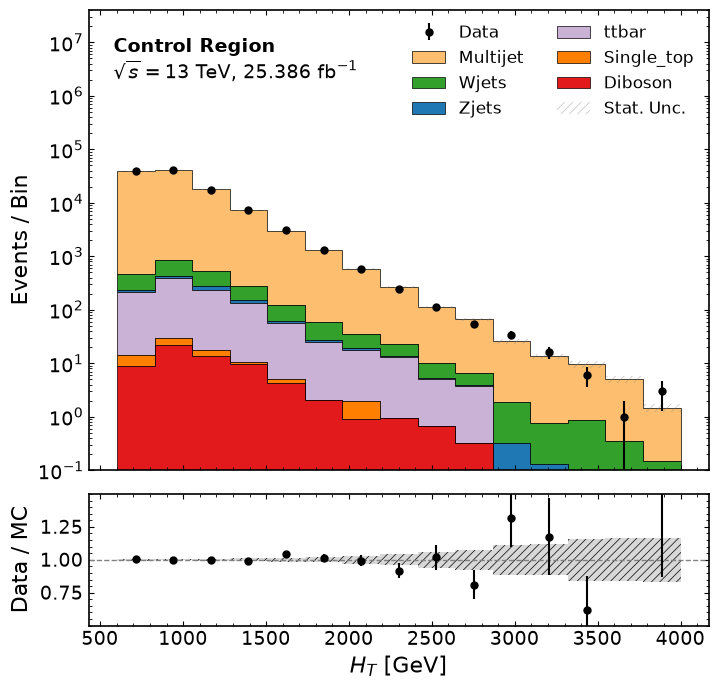

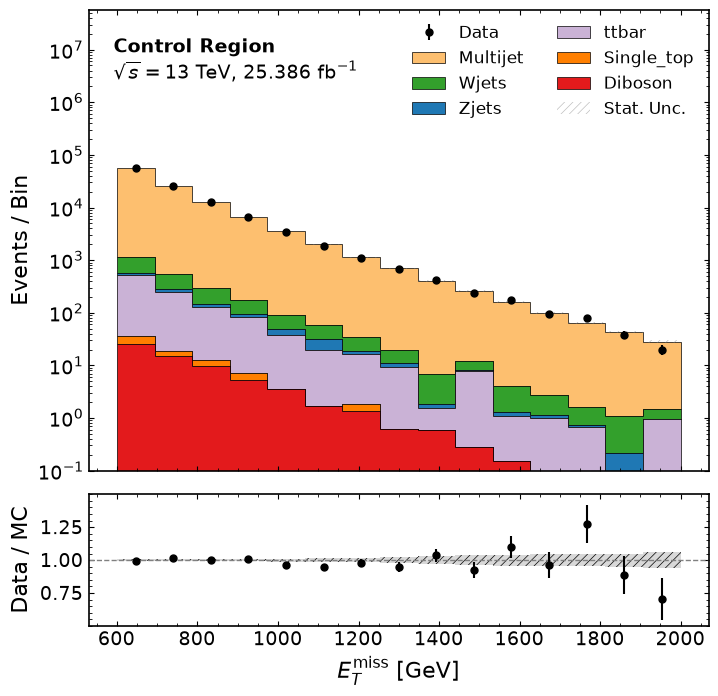

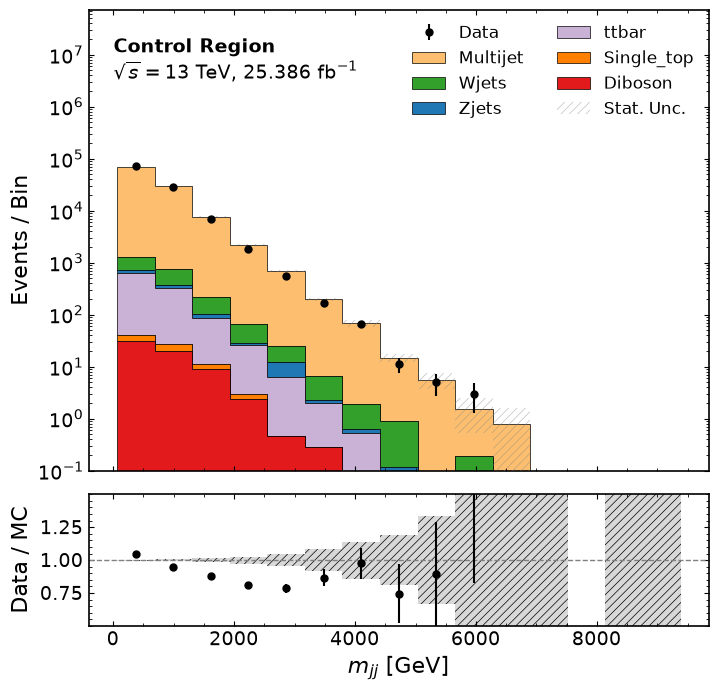

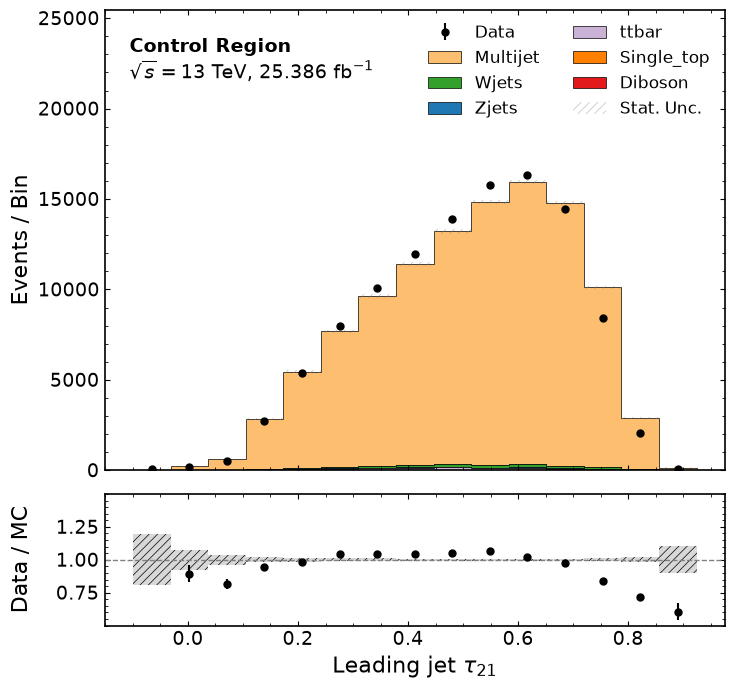

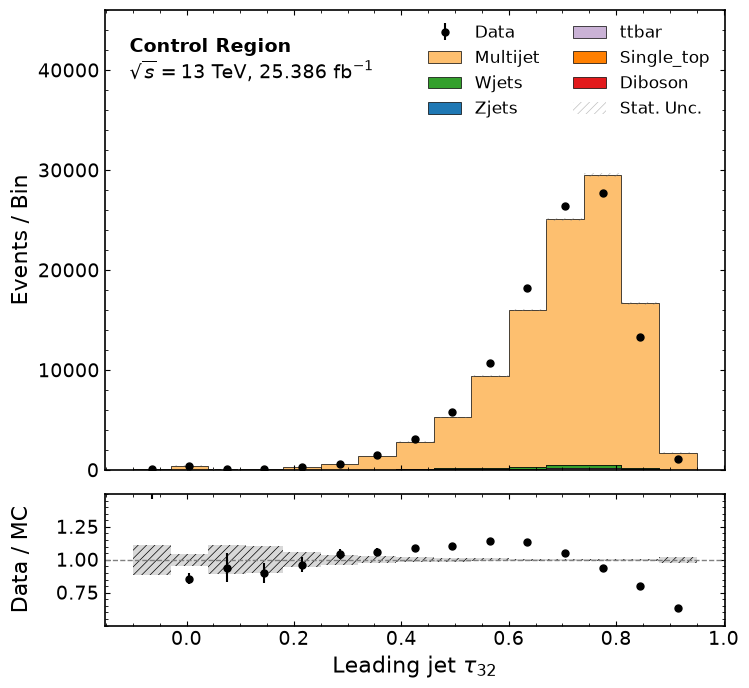

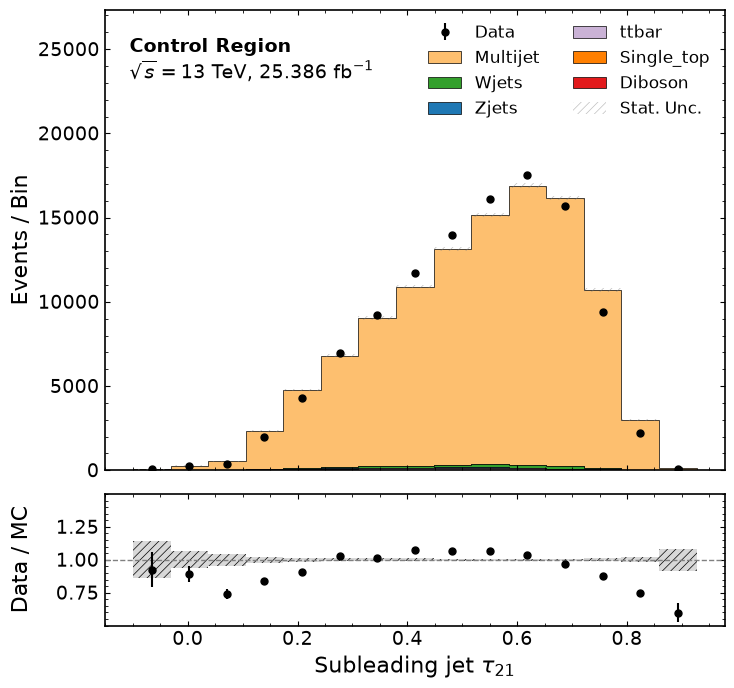

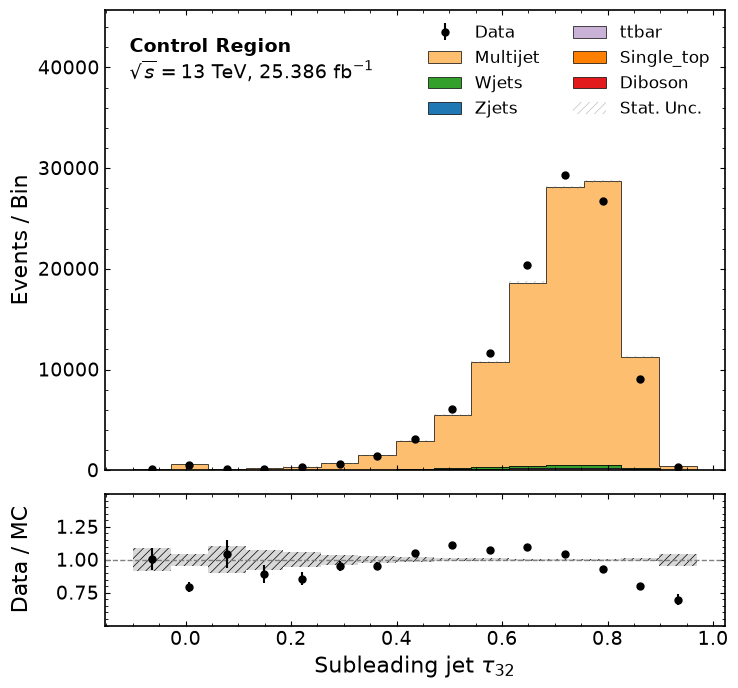

In [20]:
plot_mc_data_comparison(MC_ATLAS_TOTAL_CR_df, DATA_ATLAS_TOTAL_CR_df, "Control Region", new_lumi_ATLAS)

### Split and Scale Samples

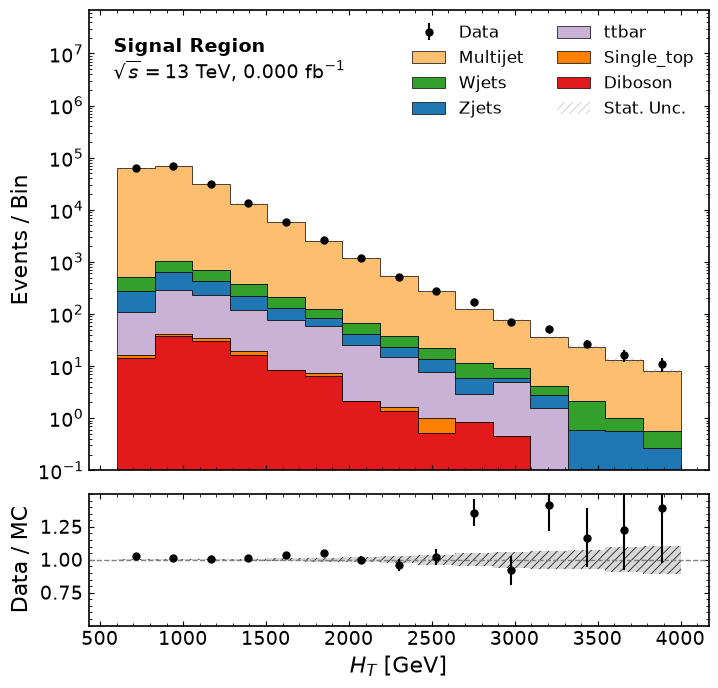

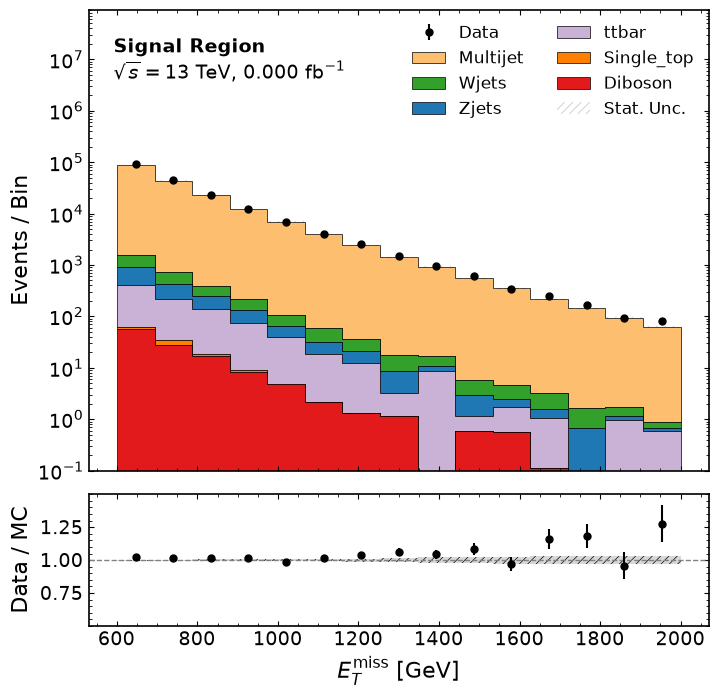

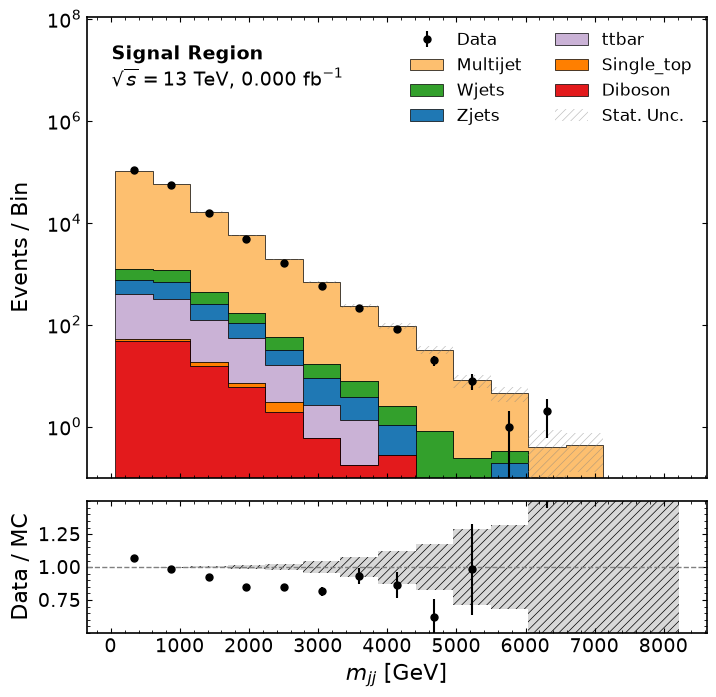

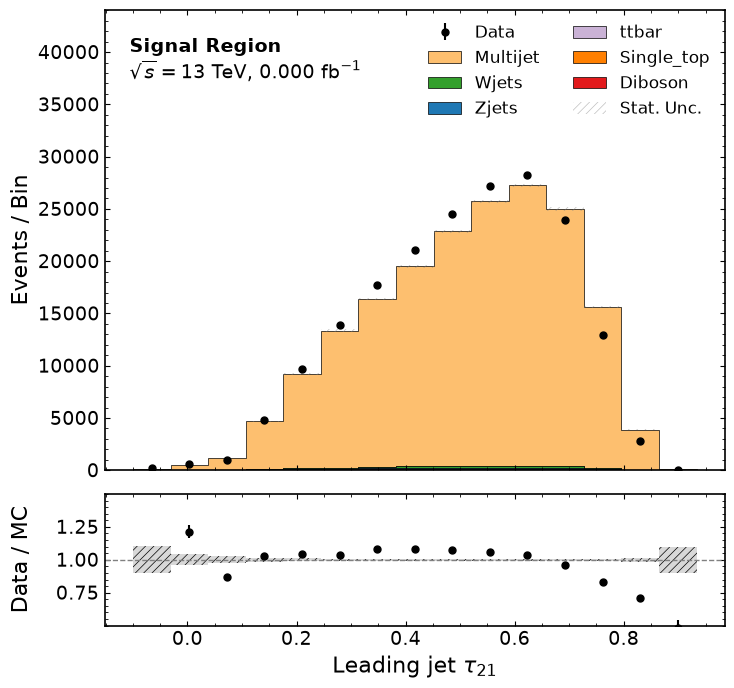

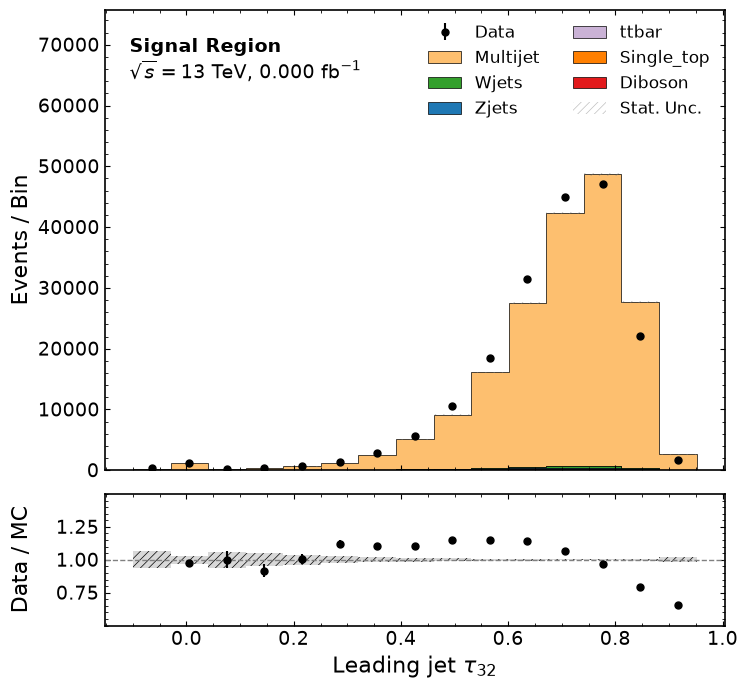

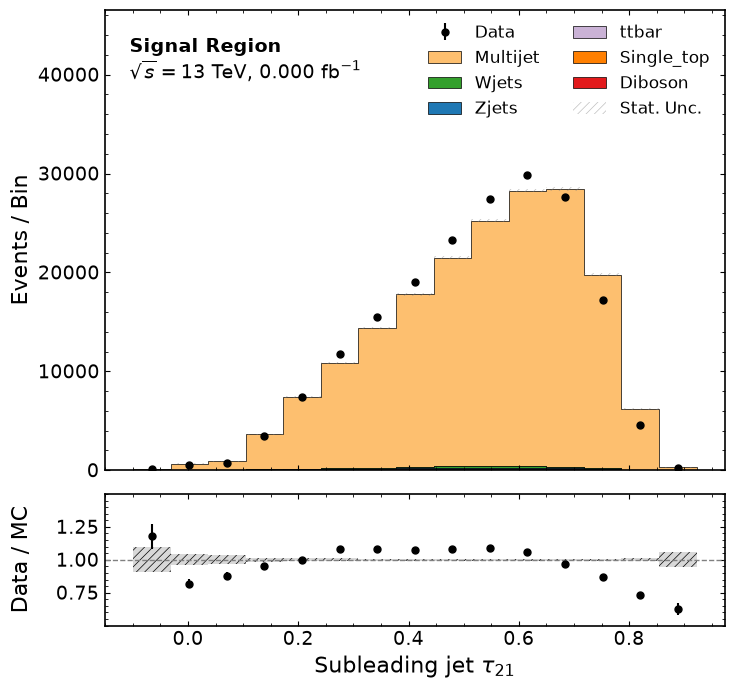

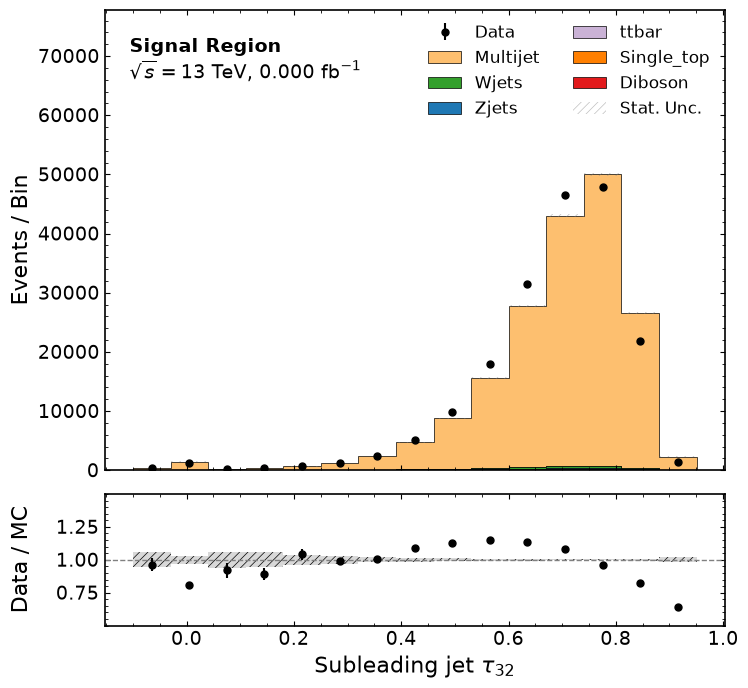

In [21]:
plot_mc_data_comparison(MC_SR_w, DATA_SR_clean, "Signal Region")

In [22]:
output_dir = Path("Final_Dataset_ATLAS")
output_dir.mkdir(parents=True, exist_ok=True)

features_to_scale = [
    'met_recalc_pt', 'ht', 
    'mjj', 'ljet1_tau21', 'ljet1_tau32', 'ljet2_tau21', 'ljet2_tau32'
]

mc_datasets = {
    "MC_CR1L": MC_ATLAS_CR1L_w,
    "MC_CR1L1B": MC_ATLAS_CR1L1B_w,
    "MC_CR2L": MC_ATLAS_CR2L_w,
    "MC_SR_clean": MC_SR_w
}

data_datasets = {
    "DATA_CR1L": DATA_ATLAS_CR1L,
    "DATA_CR1L1B": DATA_ATLAS_CR1L1B,
    "DATA_CR2L": DATA_ATLAS_CR2L,
    "DATA_SR_clean": DATA_SR_clean
}

print("="*85)
print(" 📊 DATASET STATISTICS (BEFORE SCALING)")
print("="*85)

all_mc_features = []

for name in mc_datasets.keys():
    region = name.replace("MC_", "")
    df_mc = mc_datasets[name]
    df_data = data_datasets.get(f"DATA_{region}")
    
    n_data = df_data.height if df_data is not None else 0
    
    print(f"\nREGION: {region}")
    print(f"Total Data Events: {n_data}")
    print("-" * 85)
    print(f"{'Process':<15} | {'Subprocess':<35} | {'MC Events':<10} | {'MC Yield (SumW)':<15}")
    print("-" * 85)
    
    if df_mc is not None and df_mc.height > 0:

        weight_col = "final_weight"

        mc_stats = (
            df_mc.group_by(["mc_process", "subprocess"])
            .agg([
                pl.len().alias("count"),
                pl.col(weight_col).sum().alias("yield")
            ])
            .sort(["mc_process", "subprocess"])
        )

        for row in mc_stats.iter_rows(named=True):
            print(f"{row['mc_process']:<15} | {row['subprocess']:<35} | {row['count']:<10} | {row['yield']:<15.2f}")

        all_mc_features.append(df_mc.select(features_to_scale))
    else:
        print("No MC data found for this region.")

print("\n--- Global MC Boundaries (Across All Regions) ---")

df_all_mc = pl.concat(all_mc_features)
X_all_mc = df_all_mc.to_numpy()

print(f"{'Feature':<15} | {'Global Min':<12} | {'Global Max':<12}")
print("-" * 45)
for i, f in enumerate(features_to_scale):
    f_min = X_all_mc[:, i].min()
    f_max = X_all_mc[:, i].max()
    print(f"{f:<15} | {f_min:<12.2f} | {f_max:<12.2f}")
print("="*85 + "\n")
print("Fitting MinMaxScaler on combined MC...")

# 2. ADDED CLIP=TRUE TO PREVENT ML CRASHES
scaler = MinMaxScaler(feature_range=(-2.5, 2.5), clip=True)
scaler.fit(X_all_mc)

scaler_path = output_dir / "minmax_scaler.joblib"
joblib.dump(scaler, scaler_path)
print(f"Scaler successfully saved to {scaler_path}\n")

# 3. ADDED is_mc TO FILTER OUT JUNK COLUMNS
def scale_dataframe(df: pl.DataFrame, fitted_scaler: MinMaxScaler, features: list, is_mc: bool) -> pl.DataFrame:
    """
    Extracts features, scales them using the fitted sklearn scaler, clips outliers,
    and safely overwrites the columns in the Polars DataFrame.
    """
    df_clean = df.drop_nulls(subset=features)
    X_raw = df_clean.select(features).to_numpy()

    # clip=True in MinMaxScaler handles the bounding automatically during transform
    X_scaled = fitted_scaler.transform(X_raw)

    scaled_series = [pl.Series(name=f, values=X_scaled[:, i]) for i, f in enumerate(features)]
    df_scaled = df_clean.with_columns(scaled_series)
    
    # 4. KEEP ONLY THE NEEDED COLUMNS (Drops the duplicated cross-section metadata)
    keep_cols = (["mc_process", "subprocess", "final_weight"] + features) if is_mc else features
    return df_scaled.select(keep_cols)

print("Applying scaler to all MC and Data regions and saving to Parquet...")

all_datasets = {**mc_datasets, **data_datasets}

for name, df in all_datasets.items():
    if df is None or df.height == 0:
        print(f"Skipping {name}: DataFrame is empty or missing.")
        continue

    # 5. PASS is_mc=True FOR MC FILES, False FOR DATA
    is_mc = name.startswith("MC_")
    scaled_df = scale_dataframe(df, scaler, features_to_scale, is_mc=is_mc)

    file_path = output_dir / f"{name}.parquet"
    scaled_df.write_parquet(file_path)
    
    print(f"Saved: {file_path} (Shape: {scaled_df.shape})")

print("\nPipeline complete! All data scaled and ready for PyTorch.")

 📊 DATASET STATISTICS (BEFORE SCALING)

REGION: CR1L
Total Data Events: 88582
-------------------------------------------------------------------------------------
Process         | Subprocess                          | MC Events  | MC Yield (SumW)
-------------------------------------------------------------------------------------
Diboson         | Sh_2211_WlvWqq                      | 566        | 34.64          
Diboson         | Sh_2211_WlvZqq                      | 201        | 14.60          
Diboson         | Sh_2211_WqqZvv                      | 52         | 3.00           
Diboson         | Sh_2211_ZqqZvv                      | 12         | 0.77           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ10WithSW | 174        | 0.00           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ11WithSW | 97         | 0.00           
Multijet        | Pythia8EvtGen_A14NNPDF23LO_jetjet_JZ12WithSW | 78         | 0.00           
Multijet        | Pythia8EvtGen_A14NNPDF23L